# MLC / ENGR 190W — audited Bayesian DAG research workflow

**Updated technical review.** The original retrospective experiment is preserved and rerun; added sections audit sample sizes, implement the previously missing mean baseline, retain conjugate posterior parameters, and evaluate exact Student-t **outcome-CPD** predictions for complete evidence. A tested conjugate update function illustrates sequential learning with fixed preprocessing. These additions do not turn the full joint network into a fully Bayesian missing-data model.

## Run instructions
Install packages from `requirements.txt`; put the original `Annoymized Data…zip` next to this notebook, or set environment variable `MLC_DATA_ZIP` to its path. Run All. Outputs go to `mlc_results/`. Graphviz is optional (a Matplotlib fallback is provided).

## Interpretation contract
- **191 independent student-course rows**, six terms; repeated survey/LMS rows are not independent students.
- Fixed structure, Bayesian CPD parameter estimation, plug-in joint Gaussian inference. Arrows are assumptions, not causal effects.
- Block A: 16 raw marks → 10 grade features; Block B: 23 → 16. Both include six survey/LMS features; surveys/LMS use the first four assumed course weeks.
- Assessment release timestamps and historical grade revisions are unavailable. Both blocks are retrospective release-bundle scenarios, not verified week-4 forecasts.
- Three expanding-window development folds select bundle/shrinkage among full models. Spring 2026 (43 students) is a **reused diagnostic cohort**, not a pristine test set.
- No claim of improved performance from MLC, survey/LMS factors, or causal identification. MLC availability/use, section effects, latent confounding and term hierarchy are not explicitly modeled in this experiment.
- No new model/configuration is selected using Spring 2026 results. Complete-case Student-t diagnostics are an extension, not a replacement for the original all-student metrics.


In [1]:
from pathlib import Path
import re, zipfile, itertools, json, warnings, os, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Image

SEED = 42
OUT = Path('mlc_results'); OUT.mkdir(exist_ok=True)
# Change this to your downloaded ZIP path if needed.
ZIP_PATH = Path(os.environ['MLC_DATA_ZIP']) if os.environ.get('MLC_DATA_ZIP') else next(iter(Path('.').glob('Annoymized Data*.zip')), None)
DATA_ROOT = Path('data/Annoymized Data')
if not DATA_ROOT.exists():
    if ZIP_PATH is None:
        raise FileNotFoundError('Put the supplied ZIP beside this notebook or set ZIP_PATH.')
    with zipfile.ZipFile(ZIP_PATH) as archive:
        destination = Path('data').resolve()
        for member in archive.infolist():
            resolved = (destination / member.filename).resolve()
            if not resolved.is_relative_to(destination):
                raise ValueError('Unsafe archive path')
        archive.extractall(destination)
assert DATA_ROOT.exists()
# Explicit course calendar: Monday of instructional week 1; cutoff is exclusive.
STARTS = {'2024 FAL':'2024-09-23', '2025 WTR':'2025-01-06',
          '2025 SPR':'2025-03-31', '2025 FAL':'2025-09-22',
          '2026 WTR':'2026-01-05', '2026 SPR':'2026-03-30'}
COURSES = {67191:'2024 FAL', 70375:'2025 WTR', 73052:'2025 SPR',
           76548:'2025 FAL', 80120:'2026 WTR', 82172:'2026 SPR'}
STARTS = {k:pd.Timestamp(v) for k,v in STARTS.items()}
CUTOFFS = {k:v+pd.Timedelta(weeks=4) for k,v in STARTS.items()}
def cohort_of(path):
    # Use the leading course label, not the misleading embedded SPR filename in WTR.
    match = re.search(r'(20\d{2}) (FAL|WTR|SPR)', str(path))
    if not match: raise ValueError(f'Unmapped cohort: {path}')
    return ' '.join(match.groups())
def valid_student(series):
    return series.astype('string').str.fullmatch(r'MLCStudent\d+', na=False)
print(pd.DataFrame({'week1':STARTS,'exclusive_cutoff':CUTOFFS}))

# Save reproducibility metadata without recording private filesystem locations.
versions = {p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib']}
provenance = dict(python=platform.python_version(), packages=versions,
    source_archive=ZIP_PATH.name if ZIP_PATH else None,
    archive_sha256=hashlib.sha256(ZIP_PATH.read_bytes()).hexdigest() if ZIP_PATH else None,
    seed=SEED, calendar_status='assumed; verify against instructional dates')
(OUT/'run_provenance.json').write_text(json.dumps(provenance,indent=2))


              week1 exclusive_cutoff
2024 FAL 2024-09-23       2024-10-21
2025 WTR 2025-01-06       2025-02-03
2025 SPR 2025-03-31       2025-04-28
2025 FAL 2025-09-22       2025-10-20
2026 WTR 2026-01-05       2026-02-02
2026 SPR 2026-03-30       2026-04-27


406

## 1. Expanded assessment bundles

**Block A (16 raw columns → 10 grade predictors):** NSPE quiz; both Quiz 1 sections kept separately; ethics assignment; Paper A; four checking-understanding exercises; how-to draft and three peer-work scores; Group Paper A written, oral and team evaluation marks.

**Block B (23 raw columns → 16 grade predictors):** all Block A inputs, both Quiz 2 sections kept separately, Paper B, Paper B peer work, tech-pitch reflection, and the tech-pitch written/video completion marks.

Major grades and quiz sections retain their own percentage. The four writing exercises are one points-normalized feature; early peer/draft work is another; pitch completion combines two one-point checks. These are engineered predictors, not a reconstruction of the course's weighted Current Score. Normalization uses the CSV's `Points Possible` row. Aggregation requires every component to be numeric; blanks/exemptions stay unknown, genuine zeros remain zero. Extra credit above possible points is audited, not automatically clipped.

FinalQuiz sections, Group Paper B results, final attendance totals, overall Current/Final/Unposted totals, letters, mastery aggregates, end-term feedback and unassigned/undated activities are excluded. Adding every end-of-term score would invalidate an earlier forecast. The manifest makes this restriction reviewable.

In [2]:
PATTERNS={
 'nspe':r'Quiz: National Society of Professional Engineers \(NSPE\) Code of Ethics',
 'quiz1_comm':r'Quiz#1: Section I Communications in the Professional World',
 'quiz1_ethics':r'Quiz#1: Section II Ethics',
 'ethics':r'Upload: Code of Ethics Essay(?: Outline)? Final',
 'paper_a':r'Upload: IndividualPaperA Written Paper Final',
 'critical':r'Exercise: Checking Understanding - Critical Thinking and Analysis',
 'development':r'Exercise: Checking Understanding - Development and Structure',
 'research':r'Exercise: Checking Understanding - Evidence and Research',
 'language':r'Exercise: Checking Understanding - Language Style and Convention',
 'howto_draft':r'Upload: How-To Instructions Paper Airplane Draft for Peer Editing',
 'howto_peer':r'Participation: Peer Editing How-To Paper Airplane Instructions Effort',
 'paper_a_peer':r'Participation: Peer Editing IndividualPaperA Effort',
 'group_a_peer':r'Participation: Peer Editing GroupPaperA Effort',
 'group_a_written':r'Upload: GroupPaperA Written Paper Final',
 'group_a_oral':r'Upload: GroupPaperA Oral Presentation Final',
 'group_a_team':r'Upload: GroupPaperA Team Evaluation Scoring',
 'quiz2_comm':r'Quiz#2: Section I Communications in the Professional World',
 'quiz2_ethics':r'Quiz#2: Section II Ethics',
 'paper_b':r'Upload: IndividualPaperB Written Final',
 'paper_b_peer':r'Participation: Peer Editing IndividualPaperB Effort',
 'pitch_reflection':r'Reflections: 90-sec Tech Pitch',
 'pitch_written':r'Upload: 90-Sec Technology Pitch Written Final',
 'pitch_video':r'Upload: 90-Sec Technology Pitch Video Final',
}
GROUPS={
 'nspe_pct':['nspe'],'quiz1_comm_pct':['quiz1_comm'],'quiz1_ethics_pct':['quiz1_ethics'],
 'ethics_pct':['ethics'],'paper_a_pct':['paper_a'],
 'writing_exercises_pct':['critical','development','research','language'],
 'early_peer_draft_pct':['howto_draft','howto_peer','paper_a_peer','group_a_peer'],
 'group_a_written_pct':['group_a_written'],'group_a_oral_pct':['group_a_oral'],'group_a_team_pct':['group_a_team'],
 'quiz2_comm_pct':['quiz2_comm'],'quiz2_ethics_pct':['quiz2_ethics'],
 'paper_b_pct':['paper_b'],'paper_b_peer_pct':['paper_b_peer'],
 'pitch_reflection_pct':['pitch_reflection'],'pitch_completion_pct':['pitch_written','pitch_video']}
A_GRADES=list(GROUPS)[:10];B_GRADES=list(GROUPS)
SCENARIOS={'Block A: first assessment bundle':A_GRADES,'Block B: second assessment bundle':B_GRADES}
A_KEYS={k for f in A_GRADES for k in GROUPS[f]}
B_KEYS={k for f in B_GRADES for k in GROUPS[f]}
assert len(A_KEYS)==16 and len(B_KEYS)==23

def canonical_name(c):return re.sub(r'\s+',' ',re.sub(r'\s*\(\d+\)\s*$','',c)).strip()

grade_frames=[];manifest=[];source_audit=[]
for path in sorted((DATA_ROOT/'Grades').glob('*.csv')):
 raw=pd.read_csv(path);cohort=cohort_of(path)
 meta=raw.Student.astype('string').str.strip().eq('Points Possible').fillna(False)
 assert meta.sum()==1
 d=raw.loc[valid_student(raw.Student)].copy();marks={};points={};chosen={}
 for key,pattern in PATTERNS.items():
  matches=[c for c in raw.columns if re.fullmatch(pattern,canonical_name(c))]
  assert len(matches)==1,(cohort,key,matches)
  col=matches[0];chosen[col]=key
  pts=float(pd.to_numeric(raw.loc[meta,col],errors='raise').iloc[0]);assert pts>0
  m=pd.to_numeric(d[col],errors='coerce');assert m.dropna().ge(0).all()
  marks[key]=m;points[key]=pts
  source_audit.append(dict(cohort=cohort,canonical_key=key,source_column=col,points_possible=pts,
    n_students=len(d),numeric_marks=int(m.notna().sum()),above_possible=int((m>pts).sum()),
    release_time='unknown',availability_verified=False))
 out=pd.DataFrame({'student_id':d.Student.str.strip(),'cohort':cohort,
                   'percentage':pd.to_numeric(d['Final Score'],errors='coerce')})
 for feature,keys in GROUPS.items():
  components=pd.concat([marks[k] for k in keys],axis=1)
  out[feature]=100*components.sum(axis=1,min_count=len(keys))/sum(points[k] for k in keys)
 grade_frames.append(out)
 for col in raw.columns:
  key=chosen.get(col)
  if key:
   reason='included; checkpoint assumes release of this assessment'
   a=key in A_KEYS;b=key in B_KEYS
  else:
   a=b=False
   if col=='Final Score':reason='target only'
   elif col in ['Student','ID','Section']:reason='join metadata, not a predictor'
   elif re.search(r'(Current|Final) (Score|Grade)$',col):reason='end-of-course aggregate/label; unavailable historical snapshot'
   elif col.startswith('FinalQuiz:'):reason='final quiz excluded from both earlier bundles'
   elif 'GroupPaperB' in col:reason='later Group B work excluded from these bundles'
   else:reason='release timing not established or outside selected assessment bundles'
  manifest.append(dict(cohort=cohort,source_column=col,canonical_key=key,in_block_a=a,in_block_b=b,
    decision_reason=reason,release_time='unknown'))
grades=pd.concat(grade_frames,ignore_index=True).dropna(subset=['percentage']).reset_index(drop=True)
assert not grades.duplicated(['cohort','student_id']).any()
assert grades.percentage.between(0,100).all()
assert grades.student_id.nunique()==len(grades)==191
pd.DataFrame(manifest).to_csv(OUT/'all_column_eligibility_manifest.csv',index=False)
pd.DataFrame(source_audit).to_csv(OUT/'selected_assessment_sources.csv',index=False)
display(pd.DataFrame(source_audit)[['cohort','canonical_key','points_possible','numeric_marks','above_possible']])
display(pd.DataFrame([{'checkpoint':s,'raw_assessment_columns':16 if g==A_GRADES else 23,
                      'grade_predictors':len(g)} for s,g in SCENARIOS.items()]))
PRIOR=B_GRADES
GRADE_NAMES=np.array(['D','C-','C','C+','B-','B','B+','A-','A','A+'])
GRADE_EDGES=np.array([55,60,65,70,75,80,85,90,95])
def letter_grade(p):return GRADE_NAMES[np.searchsorted(GRADE_EDGES,np.asarray(p),side='right')]


,cohort,canonical_key,points_possible,numeric_marks,above_possible
0,2024 FAL,nspe,1.0,18,0
1,2024 FAL,quiz1_comm,51.0,18,0
2,2024 FAL,quiz1_ethics,40.0,18,0
3,2024 FAL,ethics,64.0,18,0
4,2024 FAL,paper_a,64.0,18,0
...,...,...,...,...,...
133,2026 WTR,paper_b,64.0,40,0
134,2026 WTR,paper_b_peer,4.0,40,0
135,2026 WTR,pitch_reflection,16.0,40,0
136,2026 WTR,pitch_written,1.0,40,0


,checkpoint,raw_assessment_columns,grade_predictors
0,Block A: first assessment bundle,16,10
1,Block B: second assessment bundle,23,16


## 2. Wellness, motivation and engagement

Preserve the original first-four-week survey/LMS cutoff for both scenarios. This isolates the predictive contribution of the expanded grade history; it is not using unverified later surveys at the earlier checkpoint. Cost/support stays positively scored. Deduplicate repeated LMS student-week exports; aggregate only complete weeks inside the cutoff. Missing evidence is not automatically a zero. Survey timing, revised wording, ordinal wellness, voluntary nonresponse and small samples remain limitations.

The assignment manifest covers all raw gradebook columns, including those excluded. No course final/current/unposted aggregate or future final-quiz grade is used as an input.

In [3]:
survey = pd.read_csv(next((DATA_ROOT/'MLC WELL + SOM').glob('*.csv')))
survey['cohort'] = survey.lms_course_id.map(COURSES)
assert survey.cohort.notna().all()
survey['student_id'] = survey.student_name.astype('string').str.strip()
survey['submitted'] = pd.to_datetime(survey.submitted, format='mixed')
survey['answer'] = pd.to_numeric(survey.answer, errors='coerce')
assert survey.student_id.map(lambda x: bool(re.fullmatch(r'MLCStudent\d+',x))).all()
display(survey.groupby(['lms_course_id','cohort']).agg(students=('student_id','nunique'),
               first=('submitted','min'),last=('submitted','max')))
for cohort, d in survey.groupby('cohort'):
    assert ((d.submitted >= STARTS[cohort]) &
            (d.submitted < STARTS[cohort]+pd.Timedelta(weeks=13))).all()
early = survey.loc[(survey.submitted >= survey.cohort.map(STARTS)) &
                   (survey.submitted < survey.cohort.map(CUTOFFS))].copy()
key = ['cohort','student_id','submitted']
items = early[early.motivation.isin(['expectancy','value','cost'])].copy()
assert items.answer.between(1,6).all()
items = items.drop_duplicates(key+['motivation','question','answer'])
assert not items.duplicated(key+['motivation','question']).any()
sessions = items.groupby(key+['motivation']).answer.mean().unstack('motivation')
motivation = sessions.groupby(level=['cohort','student_id']).mean().rename(columns={'cost':'cost_support'})
assert early.groupby(key).wellness.nunique().le(1).all()
wellness = early.drop_duplicates(key).groupby(['cohort','student_id']).wellness.mean()
features_survey = motivation.join(wellness).reset_index()

lms_frames, lms_audits = [], []
for folder in sorted((DATA_ROOT/'LMS Activity').iterdir()):
    if not folder.is_dir(): continue
    cohort = cohort_of(folder)
    raw = pd.concat([pd.read_csv(p) for p in sorted(folder.rglob('chart.csv'))], ignore_index=True)
    raw['student_id'] = raw.Filter.str.extract(r'(MLCStudent\d+)')
    raw['week_start'] = pd.to_datetime(raw['Week Start'], format='%b %d, %Y')
    raw = raw[raw.student_id.notna()].copy()
    lk = ['student_id','week_start']
    counts = ['Page Views','Participations']
    assert raw.groupby(lk)[counts].nunique().le(1).all().all(), 'Conflicting LMS snapshots need review'
    dedup = raw.drop_duplicates(lk)
    usable = dedup[(dedup.week_start >= STARTS[cohort]) &
                   (dedup.week_start+pd.Timedelta(days=7) <= CUTOFFS[cohort])]
    grouped = usable.groupby('student_id')[counts].sum().rename(columns={
        'Page Views':'page_views','Participations':'lms_participations'})
    grouped['lms_weeks_observed'] = usable.groupby('student_id').week_start.nunique()
    grouped['cohort'] = cohort
    lms_frames.append(grouped.reset_index())
    lms_audits.append({'cohort':cohort,'raw_student_week_rows':len(raw),
                       'unique_student_weeks':len(dedup),'eligible_student_weeks':len(usable)})
lms = pd.concat(lms_frames,ignore_index=True)
assert not lms.duplicated(['cohort','student_id']).any()
frame = grades.merge(features_survey,on=['cohort','student_id'],how='left',validate='one_to_one')
frame = frame.merge(lms,on=['cohort','student_id'],how='left',validate='one_to_one')
for c in ['page_views','lms_participations']:
    assert frame[c].dropna().ge(0).all()
    frame['log_'+c] = np.log1p(frame[c])
NON_GRADE = ['wellness','cost_support','expectancy','value','log_page_views','log_lms_participations']
FEATURES = NON_GRADE + PRIOR
NODES = FEATURES + ['percentage']
assert frame.student_id.nunique() == len(frame), 'Repeated students require grouped splitting'
display(pd.DataFrame(lms_audits))
display(frame.groupby('cohort')[FEATURES].count())
display(frame[FEATURES].isna().mean().rename('missing_fraction').to_frame())
frame.to_csv(OUT/'expanded_student_features.csv', index=False)
pd.DataFrame(lms_audits).to_csv(OUT/'lms_deduplication_audit.csv',index=False)
print('Excluded auxiliary CSVs:', {name:len(list((DATA_ROOT/name).glob('*.csv')))
       for name in ['MLC Participation','MLC RETRO']})

assert 'percentage' not in FEATURES
print('Grade predictor missing counts:',frame[PRIOR].isna().sum().to_dict())


,,students,first,last
lms_course_id,cohort,,,
67191,2024 FAL,13,2024-10-12 00:24:29.212888,2024-12-09 02:42:55.670481
70375,2025 WTR,17,2025-01-17 07:00:21.602418,2025-03-17 14:54:18.231249
73052,2025 SPR,29,2025-04-10 16:41:52.582393,2025-06-09 17:52:29.810377
76548,2025 FAL,14,2025-10-09 17:05:51.019776,2025-12-08 13:55:26.549916
80120,2026 WTR,28,2026-01-15 16:17:43.884259,2026-03-16 13:52:49.029110
82172,2026 SPR,32,2026-04-09 13:19:15.607125,2026-06-08 07:29:12.164740


,cohort,raw_student_week_rows,unique_student_weeks,eligible_student_weeks
0,2024 FAL,1656,1656,72
1,2025 FAL,800,800,80
2,2025 SPR,2838,2838,172
3,2025 WTR,2028,2028,104
4,2026 SPR,616,588,168
5,2026 WTR,1040,1040,160


,wellness,cost_support,expectancy,value,log_page_views,log_lms_participations,nspe_pct,quiz1_comm_pct,quiz1_ethics_pct,ethics_pct,...,early_peer_draft_pct,group_a_written_pct,group_a_oral_pct,group_a_team_pct,quiz2_comm_pct,quiz2_ethics_pct,paper_b_pct,paper_b_peer_pct,pitch_reflection_pct,pitch_completion_pct
cohort,,,,,,,,,,,,,,,,,,,,,
2024 FAL,9,9,9,9,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
2025 FAL,11,11,11,11,20,20,20,20,20,20,...,20,20,20,20,20,20,20,20,20,20
2025 SPR,28,28,28,28,43,43,43,43,43,43,...,43,43,43,43,43,43,43,43,43,43
2025 WTR,11,11,11,11,26,26,26,27,27,27,...,27,27,27,27,27,27,27,27,27,27
2026 SPR,30,30,30,30,42,42,43,43,43,43,...,43,43,43,43,43,43,43,43,43,43
2026 WTR,24,24,24,24,40,40,40,40,40,40,...,40,40,40,40,40,40,40,40,40,40


,missing_fraction
wellness,0.408377
cost_support,0.408377
expectancy,0.408377
value,0.408377
log_page_views,0.010471
log_lms_participations,0.010471
nspe_pct,0.005236
quiz1_comm_pct,0.000000
quiz1_ethics_pct,0.000000
ethics_pct,0.000000


Excluded auxiliary CSVs: {'MLC Participation': 6, 'MLC RETRO': 1}
Grade predictor missing counts: {'nspe_pct': 1, 'quiz1_comm_pct': 0, 'quiz1_ethics_pct': 0, 'ethics_pct': 0, 'paper_a_pct': 0, 'writing_exercises_pct': 0, 'early_peer_draft_pct': 0, 'group_a_written_pct': 0, 'group_a_oral_pct': 0, 'group_a_team_pct': 0, 'quiz2_comm_pct': 0, 'quiz2_ethics_pct': 0, 'paper_b_pct': 0, 'paper_b_peer_pct': 0, 'pitch_reflection_pct': 0, 'pitch_completion_pct': 0}


## 3. Two full-factor linear Gaussian Bayesian networks

Both preserve all six psychosocial/engagement features as outcome parents along with the scenario's grade-history features. The graph is fixed and domain-specified; arrows are conditional-association assumptions, not discovered causal effects. Earlier grades are linked to expectancy and page views as a simple shared predictor subgraph. All scenario inputs also point directly to final percentage. The DAG is generated from fitted parent sets below.

The two baselines differ in coefficient shrinkage: **precision 1** and **precision 10**. Both use a Normal–Inverse-Gamma local prior, with intercept precision 0.001 and variance shape 2, scale 1, in standardized training units. Stronger shrinkage is useful when the expanded grade history has correlated predictors and the first development fit has only 45 students. No feature selection is based on Spring 2026.

The grades-only benchmark uses the same scenario history and shrinkage; a train-mean forecast is added in the audit section below. They stay benchmarks. Train-only medians/scales are fitted within each fold; constant/all-missing predictors are removed in that fold. Missing prediction-time evidence is marginalized in the joint Gaussian; training median imputation is still an approximation. Calibration below adjusts plug-in Gaussian interval scales using earlier temporal errors and does not claim guaranteed coverage or full parameter-uncertainty integration.

In [4]:
class GaussianDAG:
    def __init__(self, structure='fixed', max_parents=3, features=None, target='percentage', shrinkage=1.):
        self.structure, self.max_parents = structure, max_parents
        self.feature_list = list(FEATURES if features is None else features)
        self.target = target
        self.shrinkage = shrinkage

    def fit(self, X, y):
        self.features = [c for c in self.feature_list if X[c].notna().any() and X[c].nunique()>1]
        self.nodes = self.features + [self.target]
        self.median = X[self.features].median()
        d = X[self.features].fillna(self.median).copy()
        d[self.target] = np.asarray(y)
        self.center = d.mean().to_numpy()
        self.scale = d.std(ddof=0).to_numpy()
        self.scale[self.scale < 1e-8] = 1.
        z = (d.to_numpy()-self.center)/self.scale
        n, p = z.shape
        expert = {'wellness':[], 'cost_support':['wellness'],
                  'expectancy':['wellness','cost_support'], 'value':['expectancy'],
                  'log_page_views':['expectancy','value','cost_support'],
                  'log_lms_participations':['log_page_views'],
                  'prior_ethics_pct':['expectancy','log_page_views'],
                  'prior_paper_a_pct':['expectancy','value','log_lms_participations'],
                  'prior_quiz1_pct':['expectancy','log_page_views'], self.target:self.feature_list}
        self.parents = {}
        self.posterior = {}
        self.B = np.zeros((p,p)); intercept = np.zeros(p); noise = np.zeros(p)
        for j, node in enumerate(self.nodes):
            def design(par): return np.column_stack([np.ones(n),z[:,list(par)]])
            if self.structure == 'fixed':
                par = tuple(self.nodes.index(c) for c in expert.get(node,['expectancy','log_page_views']) if c in self.nodes[:j])
            else:
                candidates = [a for k in range(min(j,self.max_parents)+1)
                              for a in itertools.combinations(range(j),k)]
                def bic(par):
                    A = design(par)
                    coef = np.linalg.lstsq(A,z[:,j],rcond=None)[0]
                    variance = max(np.mean((z[:,j]-A@coef)**2),1e-10)
                    return n*np.log(variance)+(len(par)+2)*np.log(n)
                par = min(candidates,key=bic)
            self.parents[node] = [self.nodes[k] for k in par]
            A = design(par)
            prior_precision = np.diag([.001]+[self.shrinkage]*len(par))
            precision = prior_precision+A.T@A
            coef = np.linalg.solve(precision,A.T@z[:,j])
            a_post = 2+n/2
            b_post = 1+.5*(z[:,j]@z[:,j]-coef@precision@coef)
            assert b_post > 0
            self.posterior[node] = dict(mean=coef.copy(), precision=precision.copy(),
                a=float(a_post), b=float(b_post), parents=list(par))
            noise[j] = max(b_post/(a_post-1),1e-8)
            intercept[j] = coef[0]
            self.B[j,list(par)] = coef[1:]
        inverse = np.linalg.inv(np.eye(p)-self.B)
        self.mean = inverse@intercept
        self.cov = (inverse*noise)@inverse.T
        assert np.linalg.eigvalsh(self.cov).min()>0
        assert np.allclose(np.triu(self.B),0), 'DAG ordering violated'
        return self

    def predict_distribution(self, X):
        results=[]; t=len(self.nodes)-1
        for _, row in X.iterrows():
            evidence = np.array([k for k,c in enumerate(self.features) if pd.notna(row[c])],dtype=int)
            mean, var = self.mean[t], self.cov[t,t]
            if len(evidence):
                vals = np.array([row[self.features[k]] for k in evidence])
                vals = (vals-self.center[evidence])/self.scale[evidence]
                cross = self.cov[t,evidence]
                gain = np.linalg.solve(self.cov[np.ix_(evidence,evidence)],cross)
                mean += gain@(vals-self.mean[evidence])
                var -= gain@cross
            mean = mean*self.scale[t]+self.center[t]
            sd = np.sqrt(max(var,1e-10))*self.scale[t]
            results.append((mean,sd))
        return np.array(results)

    def edges(self):
        return [(a,b) for b,parents in self.parents.items() for a in parents]


## 4. Earlier-cohort validation chooses the checkpoint and full model

Use expanding-window folds: 2025 SPR from 2024 FAL+2025 WTR, then 2025 FAL from older terms, then 2026 WTR from older terms. Select the minimum equal-cohort-weight mean MAE **only among the four full-model configurations** (two release bundles × two shrinkage settings). The smaller benchmark cannot silently replace the full model. With only three development folds, rankings remain noisy.

The selected default prioritizes percentage accuracy. A later bundle offers less warning time and more final-total component overlap. Selecting it does not establish that waiting longer is always the best educational intervention policy. Exact calendar lead time is unknown until release dates are supplied.

In [5]:
ORDER=list(STARTS);HOLDOUT=ORDER[-1]
train=frame[frame.cohort.ne(HOLDOUT)].copy();test=frame[frame.cohort.eq(HOLDOUT)].copy()
assert len(train)==148 and len(test)==43
assert set(train.student_id).isdisjoint(test.student_id)

def metric(y,mu,sd,q=norm.ppf(.95)):
 y=np.asarray(y);point=np.clip(mu,0,100);lower=np.clip(mu-q*sd,0,100);upper=np.clip(mu+q*sd,0,100)
 return dict(n=len(y),MAE=mean_absolute_error(y,point),RMSE=np.sqrt(mean_squared_error(y,point)),
  R2=r2_score(y,point),letter_accuracy=np.mean(letter_grade(y)==letter_grade(point)),
  coverage90=np.mean((y>=lower)&(y<=upper)),width90=np.mean(upper-lower))

def fit_model(training,scenario,shrinkage,scope='Full'):
 features=(NON_GRADE if scope=='Full' else [])+SCENARIOS[scenario]
 return GaussianDAG('fixed',features=features,shrinkage=shrinkage).fit(training[features],training.percentage)

validation=[];oof=[]
for i in range(2,5):
 tr=frame[frame.cohort.isin(ORDER[:i])];va=frame[frame.cohort.eq(ORDER[i])]
 for scenario in SCENARIOS:
  for shrinkage in [1.,10.]:
   for scope in ['Full','Grades only']:
    model=fit_model(tr,scenario,shrinkage,scope)
    mu,sd=model.predict_distribution(va[model.feature_list]).T
    validation.append(dict(cohort=ORDER[i],scenario=scenario,shrinkage=shrinkage,scope=scope,
                           **metric(va.percentage,mu,sd)))
    if scope=='Full':
     for sid,y,m,s in zip(va.student_id,va.percentage,mu,sd):
      oof.append(dict(cohort=ORDER[i],scenario=scenario,shrinkage=shrinkage,student_id=sid,
                      actual=y,prediction=m,sd=s,standardized_abs_error=abs(y-m)/s))
validation=pd.DataFrame(validation);oof=pd.DataFrame(oof)
summary=validation.groupby(['scope','scenario','shrinkage'])[['MAE','RMSE','coverage90']].mean().reset_index()
full_choices=summary[summary.scope.eq('Full')].sort_values(['MAE','scenario','shrinkage'])
chosen=full_choices.iloc[0]
SELECTED_SCENARIO=chosen.scenario;SELECTED_SHRINKAGE=float(chosen.shrinkage)
print('Full models: earlier-cohort validation (selection source)')
display(full_choices.round(3))
print('Grades-only benchmark validation:');display(summary[summary.scope.eq('Grades only')].round(3))
print('Default:',SELECTED_SCENARIO,'| shrinkage precision:',SELECTED_SHRINKAGE)
validation.to_csv(OUT/'temporal_validation_metrics.csv',index=False)
summary.to_csv(OUT/'validation_summary.csv',index=False)
oof.to_csv(OUT/'temporal_out_of_fold_predictions.csv',index=False)
(OUT/'selected_configuration.json').write_text(json.dumps(dict(scenario=SELECTED_SCENARIO,
 shrinkage=SELECTED_SHRINKAGE,selection='minimum macro earlier-cohort MAE among full models'),indent=2))


Full models: earlier-cohort validation (selection source)


,scope,scenario,shrinkage,MAE,RMSE,coverage90
3,Full,Block B: second assessment bundle,10.0,3.087,3.685,0.866
2,Full,Block B: second assessment bundle,1.0,3.334,4.070,0.750
1,Full,Block A: first assessment bundle,10.0,3.628,4.544,0.929
0,Full,Block A: first assessment bundle,1.0,3.781,4.790,0.921


Grades-only benchmark validation:


,scope,scenario,shrinkage,MAE,RMSE,coverage90
4,Grades only,Block A: first assessment bundle,1.0,3.638,4.517,0.922
5,Grades only,Block A: first assessment bundle,10.0,3.497,4.358,0.953
6,Grades only,Block B: second assessment bundle,1.0,3.095,3.806,0.782
7,Grades only,Block B: second assessment bundle,10.0,2.992,3.567,0.874


Default: Block B: second assessment bundle | shrinkage precision: 10.0


143

## 5. All 43 actual-versus-predicted percentages

The default is already frozen before this cell examines Spring 2026 outcomes. Report every full configuration for transparency, without switching based on these reused diagnostic results. Main predictions use the full model; grades-only forecasts are displayed in a separate comparison column.

The 90% empirical interval multiplier is learned only from the selected configuration's 103 past out-of-time errors, using rank ceil((n+1)×0.90). Model selection and calibration share development folds; cohorts can drift, so coverage is exploratory rather than guaranteed. The original Gaussian interval and the empirically calibrated interval are kept distinct.

Reused Spring 2026 diagnostics (not selection):


,scope,scenario,shrinkage,n,MAE,RMSE,R2,letter_accuracy,coverage90,width90
0,Full,Block A: first assessment bundle,1.0,43,3.830,6.583,0.673,0.488,0.907,13.462
1,Grades only,Block A: first assessment bundle,1.0,43,3.830,6.635,0.668,0.442,0.930,13.630
2,Full,Block A: first assessment bundle,10.0,43,3.908,6.692,0.662,0.442,0.930,14.047
3,Grades only,Block A: first assessment bundle,10.0,43,3.935,6.739,0.658,0.419,0.930,14.202
4,Full,Block B: second assessment bundle,1.0,43,2.693,4.819,0.825,0.581,0.884,9.291
5,Grades only,Block B: second assessment bundle,1.0,43,2.726,4.968,0.814,0.605,0.884,9.375
6,Full,Block B: second assessment bundle,10.0,43,2.832,4.920,0.817,0.581,0.907,10.021
7,Grades only,Block B: second assessment bundle,10.0,43,2.819,5.033,0.809,0.605,0.884,10.102


,method,n,MAE,RMSE,R2,letter_accuracy,coverage90,width90
0,Plug-in Gaussian,43,2.832,4.92,0.817,0.581,0.907,10.021
1,Past temporal errors calibrated,43,2.832,4.92,0.817,0.581,0.907,11.742


,Student ID,Cohort,Actual final %,Predicted final % — full model,Predicted final % — grades benchmark,Absolute error — full model,Lower 90% — empirical,Upper 90% — empirical,Actual letter,Predicted letter
0,MLCStudent24,2026 SPR,20.01,45.69,46.49,25.68,39.80,51.58,D,D
1,MLCStudent63,2026 SPR,68.03,77.51,78.11,9.48,71.63,83.40,C+,B
2,MLCStudent67,2026 SPR,74.57,76.07,76.67,1.50,70.18,81.96,B-,B
3,MLCStudent18,2026 SPR,75.13,71.46,71.15,3.67,65.60,77.32,B,B-
4,MLCStudent162,2026 SPR,75.48,74.72,75.28,0.76,68.86,80.59,B,B-
5,MLCStudent171,2026 SPR,75.70,83.76,83.24,8.06,77.87,89.64,B,B+
6,MLCStudent189,2026 SPR,75.85,82.63,83.18,6.78,76.74,88.52,B,B+
7,MLCStudent122,2026 SPR,75.95,71.24,70.82,4.71,65.37,77.10,B,B-
8,MLCStudent147,2026 SPR,80.49,81.66,81.19,1.17,75.78,87.55,B+,B+
9,MLCStudent185,2026 SPR,80.76,82.76,82.05,2.00,76.90,88.62,B+,B+


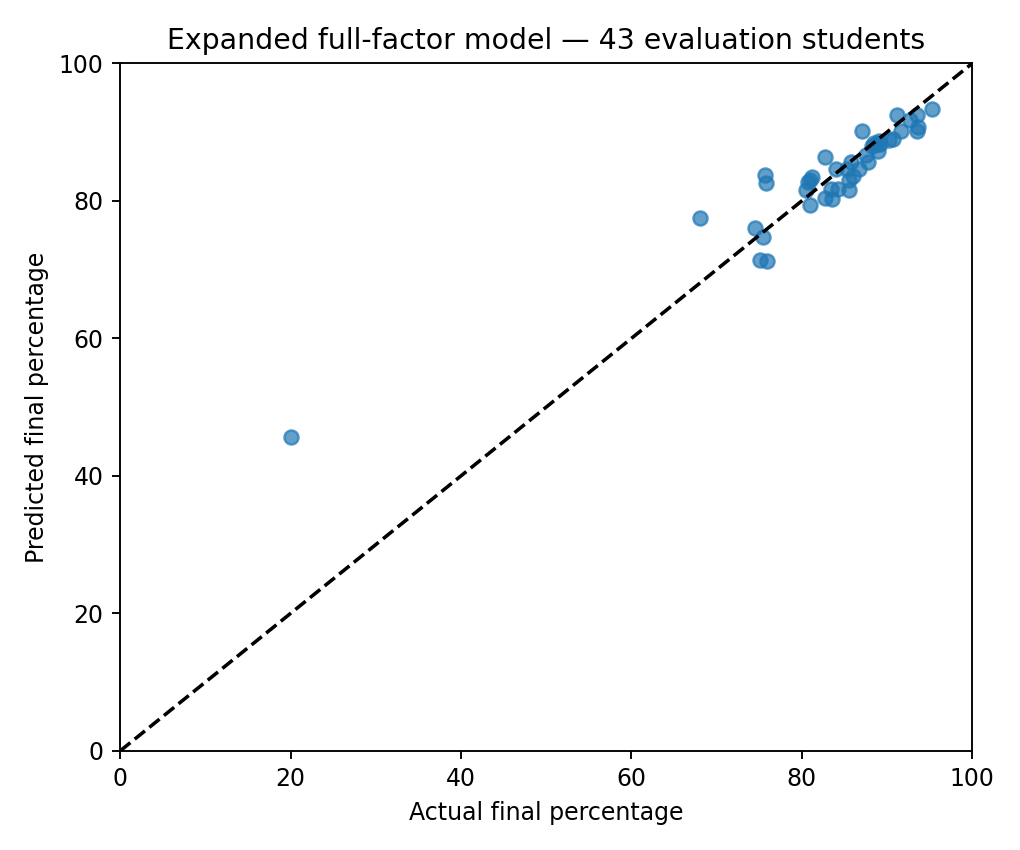

In [6]:
diagnostics=[]
for scenario in SCENARIOS:
 for shrinkage in [1.,10.]:
  for scope in ['Full','Grades only']:
   m=fit_model(train,scenario,shrinkage,scope);mu,sd=m.predict_distribution(test[m.feature_list]).T
   diagnostics.append(dict(scope=scope,scenario=scenario,shrinkage=shrinkage,**metric(test.percentage,mu,sd)))
diagnostics=pd.DataFrame(diagnostics)
print('Reused Spring 2026 diagnostics (not selection):');display(diagnostics.round(3))
diagnostics.to_csv(OUT/'reused_evaluation_metrics.csv',index=False)
selected_model=fit_model(train,SELECTED_SCENARIO,SELECTED_SHRINKAGE)
assert set(NON_GRADE).issubset(selected_model.parents['percentage'])
mu,sd=selected_model.predict_distribution(test[selected_model.feature_list]).T
benchmark=fit_model(train,SELECTED_SCENARIO,SELECTED_SHRINKAGE,'Grades only')
benchmark_mu,_=benchmark.predict_distribution(test[benchmark.feature_list]).T
calibration=oof[oof.scenario.eq(SELECTED_SCENARIO)&oof.shrinkage.eq(SELECTED_SHRINKAGE)]
assert len(calibration)==103 and set(calibration.student_id).isdisjoint(test.student_id)
rank=int(np.ceil((len(calibration)+1)*.90));calibration_q=float(np.sort(calibration.standardized_abs_error)[rank-1])
interval_comparison=pd.DataFrame([
 dict(method='Plug-in Gaussian',**metric(test.percentage,mu,sd)),
 dict(method='Past temporal errors calibrated',**metric(test.percentage,mu,sd,q=calibration_q))])
display(interval_comparison.round(3));interval_comparison.to_csv(OUT/'interval_diagnostics.csv',index=False)
predictions=pd.DataFrame({'Student ID':test.student_id.to_numpy(),'Cohort':test.cohort.to_numpy(),
 'Actual final %':test.percentage.to_numpy(),'Predicted final % — full model':np.clip(mu,0,100),
 'Predicted final % — grades benchmark':np.clip(benchmark_mu,0,100),
 'Absolute error — full model':np.abs(test.percentage.to_numpy()-np.clip(mu,0,100)),
 'Lower 90% — empirical':np.clip(mu-calibration_q*sd,0,100),
 'Upper 90% — empirical':np.clip(mu+calibration_q*sd,0,100),
 'Actual letter':letter_grade(test.percentage),'Predicted letter':letter_grade(np.clip(mu,0,100))})
with pd.option_context('display.max_rows',100,'display.max_columns',20,'display.width',200):display(predictions.round(2))
predictions.to_csv(OUT/'all_43_actual_and_predicted_percentages.csv',index=False)
fig,ax=plt.subplots(figsize=(6,5));ax.scatter(test.percentage,np.clip(mu,0,100),alpha=.7)
ax.plot([0,100],[0,100],'k--');ax.set(xlim=(0,100),ylim=(0,100),xlabel='Actual final percentage',
 ylabel='Predicted final percentage',title='Expanded full-factor model — 43 evaluation students')
plt.tight_layout();plt.savefig(OUT/'actual_vs_predicted.png',dpi=170);plt.show()

display(Image(filename=str(OUT/"actual_vs_predicted.png")))


## 6. Training-only correlations and the fitted DAG

Correlations use observed pairs from earlier cohorts only. Grade components contribute to final percentage, so strong associations partly reflect arithmetic overlap. A correlation is not a causal arrow-selection rule. The fixed graph is the same modeling policy for both shrinkage settings; shrinkage changes coefficients, not the intended relationships.

The diagram below is exported from **the actual fitted parent sets**. It includes every nonconstant predictor in the chosen bundle, plus wellness, motivation and engagement. Some grade inputs are pooled engineered summaries of multiple raw columns; see GROUPS and the full source manifest for exact provenance. The SVG can be enlarged to inspect the expanded graph.

,feature,n,Pearson,Spearman
18,paper_b_pct,148,0.691,0.684
13,group_a_written_pct,148,0.640,0.645
15,group_a_team_pct,148,0.452,0.535
10,paper_a_pct,148,0.571,0.522
9,ethics_pct,148,0.480,0.417
16,quiz2_comm_pct,148,0.450,0.406
12,early_peer_draft_pct,148,0.411,0.369
14,group_a_oral_pct,148,0.351,0.367
19,paper_b_peer_pct,148,0.427,0.328
17,quiz2_ethics_pct,148,0.428,0.321


,feature,standardized_outcome_coefficient
0,wellness,0.0250
1,cost_support,-0.0274
2,expectancy,-0.0064
3,value,-0.0166
4,log_page_views,0.0432
5,log_lms_participations,-0.0122
6,nspe_pct,0.0525
7,quiz1_comm_pct,0.0160
8,quiz1_ethics_pct,0.0684
9,ethics_pct,0.1061


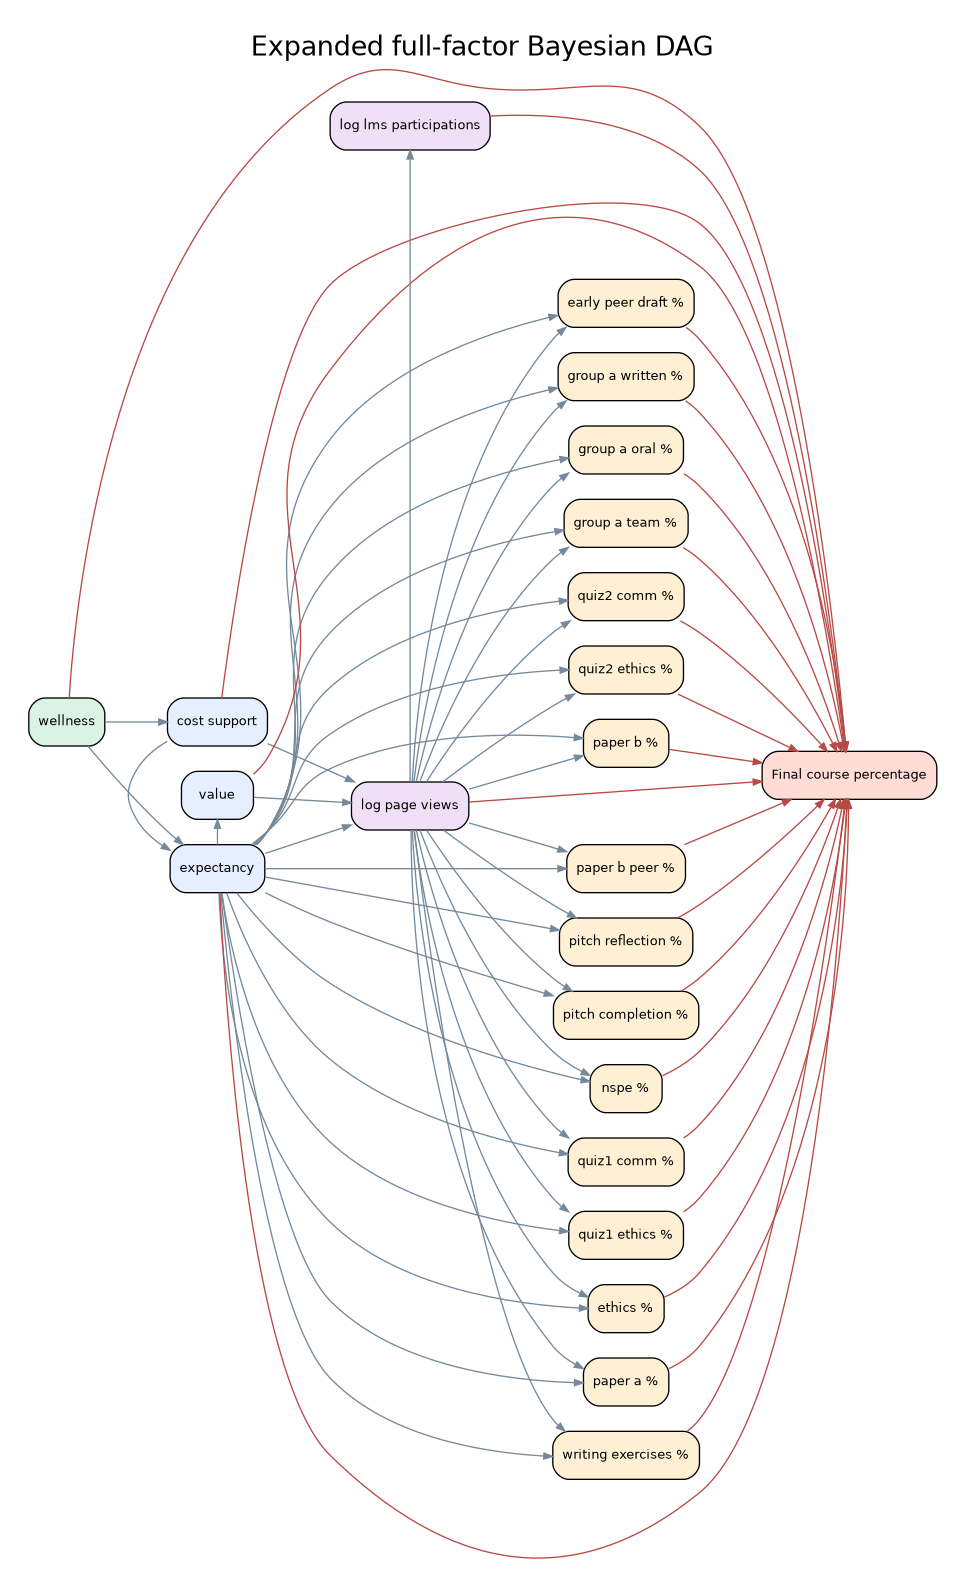

Fitted DAG: 23 nodes; 62 edges


In [7]:
correlations=[]
for feature in selected_model.features:
 pair=train[[feature,'percentage']].dropna()
 if len(pair)>=4 and pair[feature].nunique()>1:
  pr,pp=pearsonr(pair[feature],pair.percentage);sr,sp=spearmanr(pair[feature],pair.percentage)
  correlations.append(dict(feature=feature,n=len(pair),Pearson=pr,Spearman=sr))
correlations=pd.DataFrame(correlations).sort_values('Spearman',key=lambda s:s.abs(),ascending=False)
display(correlations.round(3));correlations.to_csv(OUT/'training_correlations.csv',index=False)
coefficients=pd.DataFrame({'feature':selected_model.features,'standardized_outcome_coefficient':selected_model.B[-1,:-1]})
display(coefficients.round(4));coefficients.to_csv(OUT/'full_model_coefficients.csv',index=False)
import shutil,subprocess
parents=selected_model.parents
(OUT/'fitted_DAG_parents.json').write_text(json.dumps(parents,indent=2))
colors={c:'#e6efff' for c in selected_model.nodes}
colors.update({c:'#fff0d4' for c in SCENARIOS[SELECTED_SCENARIO]})
colors.update({'wellness':'#dbf3e2','log_page_views':'#f0e0f7','log_lms_participations':'#f0e0f7','percentage':'#ffdcd5'})
lines=['digraph Model {',
 'graph [rankdir=LR,bgcolor="white",pad=0.3,nodesep=0.26,ranksep=0.65,splines=true,fontname="DejaVu Sans",labelloc=t,label="Expanded full-factor Bayesian DAG",fontsize=20];',
 'node [shape=box,style="rounded,filled",fontname="DejaVu Sans",fontsize=10,margin="0.10,0.07"];',
 'edge [color="#75899b",arrowsize=.65];']
for node in selected_model.nodes:
 label=node.replace('_pct',' %').replace('_',' ')
 if node=='percentage':label='Final course percentage'
 lines.append(f'{node} [label="{label}",fillcolor="{colors[node]}"];')
lines+=['{rank=same;cost_support;expectancy;value;}',
        '{rank=same;log_page_views;log_lms_participations;}',
        '{rank=same;'+ ';'.join(c for c in SCENARIOS[SELECTED_SCENARIO] if c in selected_model.nodes)+';}']
for b,ps in parents.items():
 for a in ps:
  style=' [color="#b84a45"]' if b=='percentage' else ''
  lines.append(f'{a} -> {b}{style};')
lines.append('}')
path=OUT/'expanded_full_DAG.dot';path.write_text(chr(10).join(lines))
if shutil.which('dot'):
 for fmt in ['png','svg']:subprocess.run(['dot',f'-T{fmt}',str(path),'-o',str(OUT/f'expanded_full_DAG.{fmt}')],check=True)
 from IPython.display import Image
 display(Image(filename=str(OUT/'expanded_full_DAG.png')))
else:
 # All actual nodes and edges, without requiring a Graphviz installation.
 positions={node:(i%5,-i//5) for i,node in enumerate(selected_model.nodes)}
 fig,ax=plt.subplots(figsize=(18,12))
 for b,ps in parents.items():
  for a in ps:ax.annotate('',xy=positions[b],xytext=positions[a],arrowprops={'arrowstyle':'->','alpha':.35,'shrinkA':25,'shrinkB':25,'connectionstyle':'arc3,rad=.1'})
 for node,(x,y) in positions.items():ax.text(x,y,node.replace('_',chr(10)),ha='center',va='center',fontsize=7,bbox={'boxstyle':'round','facecolor':colors[node]})
 ax.set(xlim=(-.6,4.6),ylim=(-6,.5),title='Expanded full-factor DAG');ax.axis('off')
 plt.tight_layout();plt.savefig(OUT/'expanded_full_DAG.png',dpi=180);plt.savefig(OUT/'expanded_full_DAG.svg');plt.show()
print('Fitted DAG:',len(parents),'nodes;',sum(map(len,parents.values())),'edges')


## 7. Verification, use and limits

The full model remains the main output regardless of benchmark scores. All six wellness/motivation/engagement variables must be included in its outcome CPD. Predict from scenario feature percentages using `selected_model.predict_distribution(...)`; use the source manifest and GROUPS to convert raw marks. Unknown evidence stays NaN and is marginalized. Do not fill a real earlier zero with a final revised mark or invent prior-course history.

The default model uses more assessments because the user prioritized prediction accuracy. Its checkpoint is later and less useful for early intervention. Do not present any improvement over the three-grade baseline as a controlled modeling gain: it also uses later and more extensive outcome components. The two bundles compare different evidence windows, not a causal intervention. Exact lead time is not known.

Final exam/Quiz sections, Group Paper B outcomes, current/final course aggregates and letter labels stay out of both input sets. In Block B, Paper B is now a predictor, so evaluating it as the target would be leakage and has intentionally been removed. Future-course histories are not available. Confirm assessment release dates, preserve historic score values, and evaluate on a new cohort before operational use.

In [8]:
# Dataset isolation and no target/late-assessment leakage.
assert set(train.student_id).isdisjoint(test.student_id)
assert not set(['percentage','Final Score','Current Score','Unposted Final Score','future_paper_b_pct']) & set(selected_model.features)
assert not any('finalquiz' in c.lower() or 'group_b' in c for c in selected_model.features)
assert set(NON_GRADE).issubset(selected_model.parents['percentage'])
assert len(SCENARIOS[SELECTED_SCENARIO]) in [10,16]
assert np.allclose(np.triu(selected_model.B),0)
assert np.linalg.eigvalsh(selected_model.cov).min()>0
# Same evidence, altered evaluation labels: predictions must not change.
altered=test.copy();altered.percentage=altered.percentage.to_numpy()[::-1]
assert np.allclose(selected_model.predict_distribution(test[selected_model.feature_list]),
                   selected_model.predict_distribution(altered[selected_model.feature_list]))
# With all predictor evidence observed, the final CPD and joint conditioning agree.
complete=test[selected_model.features].dropna()
if len(complete):
 z=(complete.to_numpy()-selected_model.center[:-1])/selected_model.scale[:-1]
 intercept=selected_model.mean[-1]-selected_model.B[-1]@selected_model.mean
 expected=(intercept+z@selected_model.B[-1,:-1])*selected_model.scale[-1]+selected_model.center[-1]
 assert np.allclose(selected_model.predict_distribution(complete)[:,0],expected)
missing=pd.DataFrame([{c:np.nan for c in selected_model.feature_list}])
assert np.isfinite(selected_model.predict_distribution(missing)).all()
print('Passed: configured feature exclusions, cohort isolation, DAG/covariance and inference checks. Historical availability is NOT verified.')
print('DEFAULT:',SELECTED_SCENARIO,'| precision',SELECTED_SHRINKAGE)
print('Raw selected assessment columns:',16 if SELECTED_SCENARIO==list(SCENARIOS)[0] else 23)
print('Six psychosocial/engagement variables remain in the main model.')


Passed: configured feature exclusions, cohort isolation, DAG/covariance and inference checks. Historical availability is NOT verified.
DEFAULT: Block B: second assessment bundle | precision 10.0
Raw selected assessment columns: 23
Six psychosocial/engagement variables remain in the main model.


## 8. Added audit: sampling unit, missingness, baselines and limits

Count raw source rows separately from the 191 matched observations. Report each development fold rather than treating three folds as precise evidence of superiority. The mean baseline uses training outcomes only. Missingness may be informative: voluntary survey response can be a selection mechanism; no missing-at-random claim is justified. IDs below are anonymized source keys, not additional model inputs.

The notebook's letter thresholds are an illustrative derived mapping; letter accuracy is not validation against official recorded letter grades and is not the primary endpoint. MAE is measured in percentage points, never percent accuracy.


In [9]:
audit = frame.groupby('cohort').agg(n_students=('student_id','nunique'),
    n_rows=('student_id','size'), final_mean=('percentage','mean'))
print('Matched analysis sample:'); display(audit)
print('Raw survey item-response rows:',len(survey), '(not independent students)')
missingness = frame.groupby('cohort')[NON_GRADE].agg(lambda x:x.isna().mean())
print('Missing fractions by term:'); display(missingness.round(3))
audit.to_csv(OUT/'cohort_sample_audit.csv')
missingness.to_csv(OUT/'missingness_by_cohort.csv')
mean_baselines=[]
for i in range(2,len(ORDER)):
    tr=frame[frame.cohort.isin(ORDER[:i])]; va=frame[frame.cohort.eq(ORDER[i])]
    pred=np.repeat(tr.percentage.mean(),len(va))
    mean_baselines.append(dict(cohort=ORDER[i],n=len(va),
        role='reused diagnostic' if i==5 else 'development',
        MAE=mean_absolute_error(va.percentage,pred),
        RMSE=np.sqrt(mean_squared_error(va.percentage,pred))))
mean_baselines=pd.DataFrame(mean_baselines)
display(mean_baselines.round(3));mean_baselines.to_csv(OUT/'train_mean_baseline.csv',index=False)
print('Selected full model, fold-specific development metrics:')
display(validation[validation.scope.eq('Full') & validation.scenario.eq(SELECTED_SCENARIO)
    & validation.shrinkage.eq(SELECTED_SHRINKAGE)].round(3))
print('Maximum Spring 2026 absolute error:',predictions['Absolute error — full model'].max())
assert len(frame)==191 and frame.student_id.nunique()==191
assert len(train)==148 and len(test)==43


Matched analysis sample:


,n_students,n_rows,final_mean
cohort,,,
2024 FAL,18,18,79.912222
2025 FAL,20,20,79.708000
2025 SPR,43,43,81.932791
2025 WTR,27,27,78.361481
2026 SPR,43,43,83.461860
2026 WTR,40,40,78.927250


Raw survey item-response rows: 8976 (not independent students)
Missing fractions by term:


,wellness,cost_support,expectancy,value,log_page_views,log_lms_participations
cohort,,,,,,
2024 FAL,0.500,0.500,0.500,0.500,0.000,0.000
2025 FAL,0.450,0.450,0.450,0.450,0.000,0.000
2025 SPR,0.349,0.349,0.349,0.349,0.000,0.000
2025 WTR,0.593,0.593,0.593,0.593,0.037,0.037
2026 SPR,0.302,0.302,0.302,0.302,0.023,0.023
2026 WTR,0.400,0.400,0.400,0.400,0.000,0.000


,cohort,n,role,MAE,RMSE
0,2025 SPR,43,development,8.548,9.720
1,2025 FAL,20,development,4.902,6.657
2,2026 WTR,40,development,4.572,6.457
3,2026 SPR,43,reused diagnostic,8.128,12.048


Selected full model, fold-specific development metrics:


,cohort,scenario,shrinkage,scope,n,MAE,RMSE,R2,letter_accuracy,coverage90,width90
6,2025 SPR,Block B: second assessment bundle,10.0,Full,43,3.823,4.672,0.745,0.372,0.698,10.715
14,2025 FAL,Block B: second assessment bundle,10.0,Full,20,2.944,3.645,0.697,0.500,0.900,11.092
22,2026 WTR,Block B: second assessment bundle,10.0,Full,40,2.493,2.736,0.812,0.550,1.000,10.733


Maximum Spring 2026 absolute error: 25.68025572493549


## 9. Added uncertainty diagnostic: exact conjugate outcome prediction

For complete retained predictor evidence, the final CPD is Bayesian linear regression. Under the existing prior, $\beta\mid\sigma^2\sim N(0,\sigma^2\Lambda_0^{-1})$ and $\sigma^2\sim IG(a_0=2,b_0=1)$:

$\Lambda_n=\Lambda_0+A^TA,\quad m_n=\Lambda_n^{-1}A^Tz_y$

$y_*\mid x_*,D\sim t_{2a_n}\left(a_*^Tm_n,\sqrt{\frac{b_n}{a_n}(1+a_*^T\Lambda_n^{-1}a_*)}\right)$.

The leverage term includes coefficient uncertainty; the Student-t distribution integrates residual-variance uncertainty. These statements condition on training preprocessing and the median-imputed training design. They do **not** integrate uncertainty in missing training inputs, graph structure or scaling. Predictions with missing evidence still use the original plug-in joint Gaussian method. The code rejects incomplete evidence for the exact CPD method rather than silently treating an imputed prediction as exact. Compare each model's intervals on the **same complete-case subset**, which is selected and may differ from the original 43-student population. No promise of future coverage.

Raw Student-t predictions have unbounded support; reported endpoints are projected to [0,100] for diagnostic consistency. This is not a truncated likelihood; a bounded likelihood remains future work.


In [10]:
from scipy.stats import t as student_t

def outcome_student_t(model, X, alpha=.10):
    if X[model.features].isna().any().any():
        raise ValueError('Complete retained predictor evidence is required for exact CPD prediction.')
    p=model.posterior[model.target]
    z=(X[model.features].to_numpy()-model.center[:-1])/model.scale[:-1]
    a=np.column_stack([np.ones(len(z)),z[:,p['parents']]])
    leverage=np.einsum('ij,ji->i',a,np.linalg.solve(p['precision'],a.T))
    loc=(a@p['mean'])*model.scale[-1]+model.center[-1]
    scale=np.sqrt(p['b']/p['a']*(1+leverage))*model.scale[-1]
    df=2*p['a']; q=student_t.ppf(1-alpha/2,df)
    return pd.DataFrame(dict(mean=loc,scale=scale,df=df,
        lower=np.clip(loc-q*scale,0,100),upper=np.clip(loc+q*scale,0,100)),index=X.index)

posterior_checks=[]
for label,model in [('Full',selected_model),('Grades only',benchmark)]:
    subset=test.dropna(subset=model.features)
    assert len(subset)>0, 'No complete-evidence cases for this model'
    exact=outcome_student_t(model,subset)
    plugin_mean,plugin_sd=model.predict_distribution(subset[model.feature_list]).T
    assert np.allclose(exact['mean'],plugin_mean)
    assert np.all(exact.scale**2*exact.df/(exact.df-2) >= plugin_sd**2-1e-8)
    for method,lower,upper in [
        ('Exact outcome Student-t',exact.lower.to_numpy(),exact.upper.to_numpy()),
        ('Plug-in Gaussian, same subset',np.clip(plugin_mean-norm.ppf(.95)*plugin_sd,0,100),
         np.clip(plugin_mean+norm.ppf(.95)*plugin_sd,0,100))]:
        y=subset.percentage.to_numpy()
        posterior_checks.append(dict(model=label,method=method,n=len(y),
            MAE=mean_absolute_error(y,np.clip(exact['mean'],0,100)),
            coverage90=np.mean((y>=lower)&(y<=upper)),width90=np.mean(upper-lower)))
    exact.assign(student_id=subset.student_id,actual=subset.percentage).to_csv(
        OUT/('complete_evidence_'+label.replace(' ','_').lower()+'.csv'),index=False)
posterior_checks=pd.DataFrame(posterior_checks)
display(posterior_checks.round(3))
posterior_checks.to_csv(OUT/'complete_evidence_uncertainty_diagnostics.csv',index=False)
# The function must reject missing prediction-time evidence.
try:
    outcome_student_t(selected_model,pd.DataFrame([{c:np.nan for c in selected_model.features}]))
except ValueError:
    print('Passed: missing evidence is rejected by the exact-CPD interface.')
else:
    raise AssertionError('Incomplete evidence was incorrectly accepted')


,model,method,n,MAE,coverage90,width90
0,Full,Exact outcome Student-t,29,1.852,1.000,10.833
1,Full,"Plug-in Gaussian, same subset",29,1.852,1.000,10.008
2,Grades only,Exact outcome Student-t,43,2.819,0.907,10.717
3,Grades only,"Plug-in Gaussian, same subset",43,2.819,0.884,10.102


Passed: missing evidence is rejected by the exact-CPD interface.


## 10. Tested building block for updates; remaining research

`update_nig` updates one outcome CPD when **new labeled rows** arrive, with feature meanings, dimensions, centering and scaling frozen. It is an algebra test, not a prospective evaluation. Updating a student's evidence within a term uses `predict_distribution` and does not require final labels; parameter learning requires outcomes to become available. Do not repeatedly count the same student as a new independent observation. Do not replace an already-used weekly snapshot by appending it as another student.

Next research steps:
1. Verify the instructional calendar, assessment release/grade-revision timestamps and actual lead time; freeze a useful prediction date and produce immutable snapshots.
2. Review a learning-science DAG with domain experts. Explicitly consider prior ability, course/section context, MLC availability, use, engagement and response selection. Confounder/mediator/collider roles depend on the causal question and conditioning set; adding all nodes is not causal identification.
3. Evaluate incremental survey/LMS value at identical dates with time-matched grades-only baselines; inspect voluntary missingness, low-grade errors and term/section heterogeneity. MLC exposure/use and participation/retro data need their own timing-aware feature plan.
4. Model missing inputs and parameter uncertainty jointly, evaluate bounded/heavy-tail outcomes and partial pooling across terms/sections, and separate model-selection and interval-calibration data.
5. Freeze the workflow and evaluate on a new cohort: MAE/RMSE, predictive log score, interval coverage/width and calibration. Validate any coaching intervention in a separate study; forecasts alone do not establish intervention benefit.


In [11]:
def update_nig(state,A,y):
    # IG uses shape a and scale b; all arrays use a frozen standardized design.
    m0,L0,a0,b0=state
    Ln=L0+A.T@A
    mn=np.linalg.solve(Ln,L0@m0+A.T@y)
    an=a0+len(y)/2
    bn=b0+.5*(y@y+m0@L0@m0-mn@Ln@mn)
    assert bn>0
    return mn,Ln,an,bn

model=selected_model
X=train[model.features].fillna(model.median).to_numpy()
z=(X-model.center[:-1])/model.scale[:-1]
y=(train.percentage.to_numpy()-model.center[-1])/model.scale[-1]
A=np.column_stack([np.ones(len(z)),z])
prior=(np.zeros(A.shape[1]),np.diag([.001]+[model.shrinkage]*len(model.features)),2.,1.)
k=len(y)//2
batch=update_nig(prior,A,y)
sequential=update_nig(update_nig(prior,A[:k],y[:k]),A[k:],y[k:])
for b,s in zip(batch,sequential): np.testing.assert_allclose(b,s,rtol=1e-9,atol=1e-9)
np.testing.assert_allclose(batch[0],model.posterior[model.target]['mean'],atol=1e-9)
print('Passed: two disjoint labeled batches equal a single batch posterior under frozen preprocessing.')
print('All research checks completed. No prospective or causal claim is made.')


Passed: two disjoint labeled batches equal a single batch posterior under frozen preprocessing.
All research checks completed. No prospective or causal claim is made.
